# WHO LEADS IN MASS LITIGATION — Replication on our UNIFIED deduped data

Adapted from the Yale replication notebook. Differences from the original:

* **Input** = our `unified_mdl_database.xlsx` (exported to `../datasets_ours/*.csv`), which spans
  **MDL_old (gold)** and **MDL_new (extracted)**.
* **Scope switch** below runs the whole notebook on `old`, `new`, or `both`.
* **Our dedup is reused**: appointments already carry `Unified_Attorney_ID` and `Unified_Firm_ID`.
  The original notebook's two crude dedup steps — scraping a numeric `attorney_id` from the `attorney`
  column, and clustering firm names by token overlap — are **removed**; we use the canonical IDs, which
  makes old / new / both directly comparable.
* Everything else (pelvic-mesh collapse to 9999, plaintiff-side focus, the figures, the cycling stat)
  mirrors the original.


In [1]:
# ============================================================
# SCOPE SWITCH  --  set to "old" | "new" | "both"
# ============================================================
SCOPE = "both"

SAVE = True   # also save each figure to figures_ours/<SCOPE>/

import pandas as pd, numpy as np, matplotlib.pyplot as plt, re, os
from itertools import combinations
from collections import Counter
from pathlib import Path

pd.set_option("display.max_columns", None)
plt.rcParams.update({
    "font.family": "Times New Roman", "font.size": 11, "axes.labelsize": 12,
    "axes.titlesize": 13, "xtick.labelsize": 9, "ytick.labelsize": 10,
    "figure.dpi": 150, "axes.linewidth": 0.8, "axes.edgecolor": "black",
    "axes.spines.top": False, "axes.spines.right": False,
})

DATA = Path("../datasets_ours")
FIGDIR = Path(f"../figures_ours/{SCOPE}")
if SAVE: FIGDIR.mkdir(parents=True, exist_ok=True)
def savefig(name):
    if SAVE: plt.savefig(FIGDIR / f"{name}.png", dpi=200, bbox_inches="tight")

appointments = pd.read_csv(DATA / "appointments.csv")
attorneys    = pd.read_csv(DATA / "attorneys.csv")
orders       = pd.read_csv(DATA / "orders.csv")
mdls         = pd.read_csv(DATA / "mdls.csv")

# scope filter on the Corpus column (Appointments + Orders carry it)
def scope_filter(df):
    if SCOPE == "old":  return df[df["Corpus"] == "old"].copy()
    if SCOPE == "new":  return df[df["Corpus"] == "new"].copy()
    return df.copy()
appointments = scope_filter(appointments)
orders       = scope_filter(orders)
print(f"SCOPE={SCOPE} | appointments={len(appointments):,} | orders={len(orders):,} | "
      f"attorneys(roster)={len(attorneys):,} | mdls={len(mdls):,}")


SCOPE=both | appointments=18,886 | orders=2,037 | attorneys(roster)=3,178 | mdls=809


## 1 — Data cleaning (adapted)

We build the same analysis frames as the original — `attorney_x_mdl` (plaintiff, one row per
attorney × MDL), `firm_x_mdl` (plaintiff, one row per firm × MDL), and `appointments_attorneys`
(appointments + demographics) — **but keyed on our canonical `Unified_Attorney_ID` / `Unified_Firm_ID`**,
so the notebook's own attorney-id scrape and firm token-clustering are unnecessary.

`appoint` validity: gold rows use the human `"checked"` flag; extracted rows use `Appoint == True`
(an appointment, not a removal). Pelvic-mesh MDLs (2187, 2325, 2326, 2327, 2387, 2440) are collapsed to 9999.


In [2]:
PELVIC = [2187, 2325, 2326, 2327, 2387, 2440]

ap = appointments.copy()
ap["mdl_no"] = pd.to_numeric(ap["MDL_No"], errors="coerce").astype("Int64").replace(PELVIC, 9999)
ap["pd_side"] = ap["Plaintiff/Defendant"].astype(str).str.strip().str.lower()
ap["is_ind"]  = ap["Appointee Type"].astype(str).str.strip().eq("Individual")
def split_roles(s):
    if pd.isna(s):
        return []
    s = str(s)
    return [t.strip() for t in re.split(r"[;,]", s) if t.strip() and t.strip().lower() != "nan"]
ap["roles"]   = ap["Appointment Types"].apply(split_roles)

# appointment validity: all-extracted corpus -> Appoint True (an appointment, not a removal);
# "checked" accepted for back-compat with any gold-schema input
aps = ap["Appoint"].astype(str).str.lower()
valid = aps.isin(["true", "checked"])
ap = ap[valid & ap["mdl_no"].notna()].copy()

name_map = attorneys.set_index("Attorney_ID")["Canonical_Name"]

# ---- attorney x MDL (plaintiff, individuals) ----
ax = ap[ap["is_ind"] & ap["pd_side"].eq("plaintiff") &
        ap["Unified_Attorney_ID"].astype(str).ne("") & ap["Unified_Attorney_ID"].notna()].copy()
ax["attorney_id"] = ax["Unified_Attorney_ID"].astype(str)
ax["canonical_name"] = ax["attorney_id"].map(name_map).fillna(ax["First_Last_Calculated"])

def union_roles(series):
    s = set()
    for L in series: s |= set(L)
    return sorted(s)

attorney_x_mdl = (ax.groupby(["attorney_id", "mdl_no"])
    .agg(canonical_name=("canonical_name", "first"),
         roles=("roles", union_roles),
         firm_id=("Unified_Firm_ID", "first"))
    .reset_index())
attorney_x_mdl["is_lead"] = attorney_x_mdl["roles"].apply(lambda r: "LeadCounsel" in r)

demo = attorneys[["Attorney_ID", "Gender", "Birth_Year", "Undergrad_School",
                  "Law_School_Name", "Bar_States"]].rename(columns=str.lower)
attorney_x_mdl = attorney_x_mdl.merge(demo, left_on="attorney_id", right_on="attorney_id", how="left")

# ---- firm x MDL (plaintiff) ----
fx = ap[ap["pd_side"].eq("plaintiff") &
        ap["Unified_Firm_ID"].astype(str).ne("") & ap["Unified_Firm_ID"].notna()].copy()
fx["firm_id"] = fx["Unified_Firm_ID"].astype(str)
firm_name = fx.groupby("firm_id")["Firm"].agg(lambda s: s.astype(str).value_counts().idxmax())
firm_x_mdl = fx[["firm_id", "mdl_no"]].drop_duplicates().copy()
firm_x_mdl["firm"] = firm_x_mdl["firm_id"].map(firm_name)

# ---- appointments + demographics (for appendix: bar state / gender / age; both sides, individuals) ----
appointments_attorneys = ap[ap["is_ind"]].merge(
    attorneys, left_on="Unified_Attorney_ID", right_on="Attorney_ID", how="left", suffixes=("", "_att"))

print(f"attorney_x_mdl: {len(attorney_x_mdl):,} rows | {attorney_x_mdl['attorney_id'].nunique():,} attorneys | "
      f"{attorney_x_mdl['mdl_no'].nunique():,} MDLs")
print(f"firm_x_mdl:     {len(firm_x_mdl):,} rows | {firm_x_mdl['firm_id'].nunique():,} firms")
print(f"appointments_attorneys: {len(appointments_attorneys):,} rows")
attorney_x_mdl.head()


attorney_x_mdl: 5,098 rows | 2,487 attorneys | 454 MDLs
firm_x_mdl:     4,534 rows | 1,298 firms
appointments_attorneys: 9,851 rows


,attorney_id,mdl_no,canonical_name,roles,firm_id,is_lead,gender,birth_year,undergrad_school,law_school_name,bar_states
0,A0001,1657,Christopher A. Seeger,"[Fees, LeadCounsel, Management]",F0009,True,male,1960.0,CUNY,YESHIVA,"NJ-1990, NY-1991"
1,A0001,1699,Christopher A. Seeger,[Management],None,False,male,1960.0,CUNY,YESHIVA,"NJ-1990, NY-1991"
2,A0001,1708,Christopher A. Seeger,[Management],F0009,False,male,1960.0,CUNY,YESHIVA,"NJ-1990, NY-1991"
3,A0001,1742,Christopher A. Seeger,[Management],F0009,False,male,1960.0,CUNY,YESHIVA,"NJ-1990, NY-1991"
4,A0001,1789,Christopher A. Seeger,"[Communications, Management]",F0009,False,male,1960.0,CUNY,YESHIVA,"NJ-1990, NY-1991"


## 2 — Main paper figures (6–13)

### Figure 6 — Distribution of repeated co-appointment across MDLs (attorneys)

attorney pairs that never co-appear: 3,040,892; that co-appear >=1: 50,449


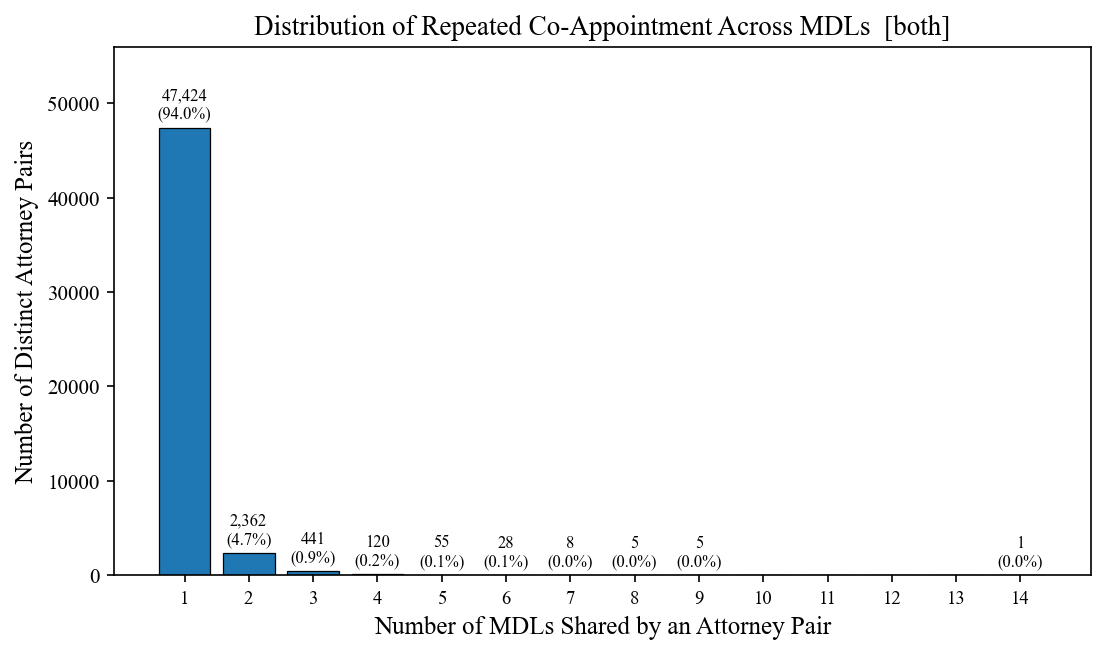

In [3]:
df = attorney_x_mdl.copy()
mdl_slates = df.groupby("mdl_no")["attorney_id"].apply(set)
attys = sorted(df["attorney_id"].unique())
pair_counts = Counter()
for s in mdl_slates:
    for pair in combinations(sorted(s), 2):
        pair_counts[pair] += 1
shared = pd.Series(list(pair_counts.values()))
dist = shared[shared > 0].value_counts().sort_index()
if len(dist):
    dist = dist.reindex(range(1, dist.index.max() + 1), fill_value=0)
n_nonzero = int(dist.sum())
n_zero = int(len(list(combinations(attys, 2))) - n_nonzero)
print(f"attorney pairs that never co-appear: {n_zero:,}; that co-appear >=1: {n_nonzero:,}")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
bars = ax.bar(dist.index, dist.values, width=0.8, edgecolor="black", linewidth=0.6)
ymax = max(1, dist.values.max()) * 1.18
ax.set_ylim(0, ymax)
ax.set_title(f"Distribution of Repeated Co-Appointment Across MDLs  [{SCOPE}]")
ax.set_xlabel("Number of MDLs Shared by an Attorney Pair"); ax.set_ylabel("Number of Distinct Attorney Pairs")
ax.set_xticks(dist.index)
for sp in ax.spines.values(): sp.set_visible(True); sp.set_linewidth(0.8)
for bar in bars:
    c = int(bar.get_height())
    if c > 0:
        ax.text(bar.get_x()+bar.get_width()/2, c + 0.01*ymax, f"{c:,}\n({c/n_nonzero*100:.1f}%)",
                ha="center", va="bottom", fontsize=8)
plt.tight_layout(); savefig("fig06_attorney_coappt_dist"); plt.show()


### Figure 7 — Co-appointment heatmap, top-20 attorney pairs

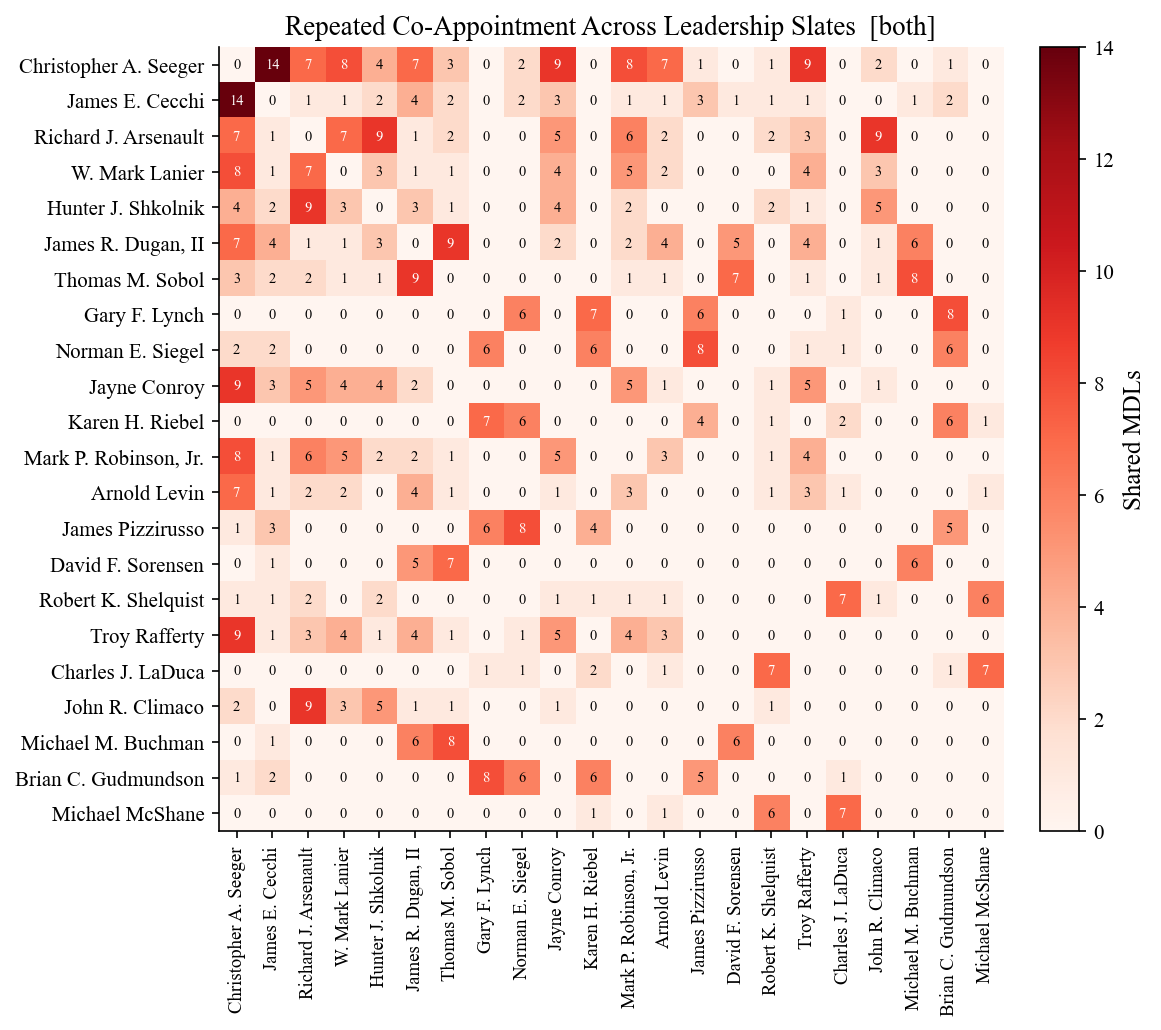

In [4]:
df = attorney_x_mdl.copy()
mdl_slates = df.groupby("mdl_no")["attorney_id"].apply(lambda x: sorted(set(x)))
pc = Counter()
for s in mdl_slates:
    for a, b in combinations(s, 2): pc[(a, b)] += 1
pair_df = pd.DataFrame([(a, b, c) for (a, b), c in pc.items()], columns=["i", "j", "n"])
top20 = pair_df.sort_values("n", ascending=False).head(20)
top = sorted(set(top20["i"]) | set(top20["j"]))
id_name = df.drop_duplicates("attorney_id").set_index("attorney_id")["canonical_name"]
if top:
    m = (pair_df[pair_df["i"].isin(top) & pair_df["j"].isin(top)]
         .pivot(index="i", columns="j", values="n").fillna(0))
    m = m.add(m.T, fill_value=0).reindex(index=top, columns=top, fill_value=0).fillna(0)
    m.index = [id_name.get(i, i) for i in m.index]; m.columns = [id_name.get(c, c) for c in m.columns]
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(m.values, cmap="Reds", vmin=0); ax.set_aspect("equal")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label("Shared MDLs")
    ax.set_xticks(range(len(m.columns))); ax.set_yticks(range(len(m.index)))
    ax.set_xticklabels(m.columns, rotation=90); ax.set_yticklabels(m.index)
    ax.set_title(f"Repeated Co-Appointment Across Leadership Slates  [{SCOPE}]")
    mx = m.values.max()
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = int(m.values[i, j])
            ax.text(j, i, v, ha="center", va="center", fontsize=7,
                    color="white" if v >= mx*0.5 and v > 0 else "black")
    plt.tight_layout(); savefig("fig07_attorney_heatmap"); plt.show()
else:
    print("no co-appointing attorney pairs in scope")


### Figure 8 — Prevalence of one-off collaborations (top-20 attorneys)

/var/folders/k7/b0_b7t6j6n72t68sh4s7t8400000gn/T/ipykernel_87675/939289800.py:20: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(summ["attorney"], rotation=90)


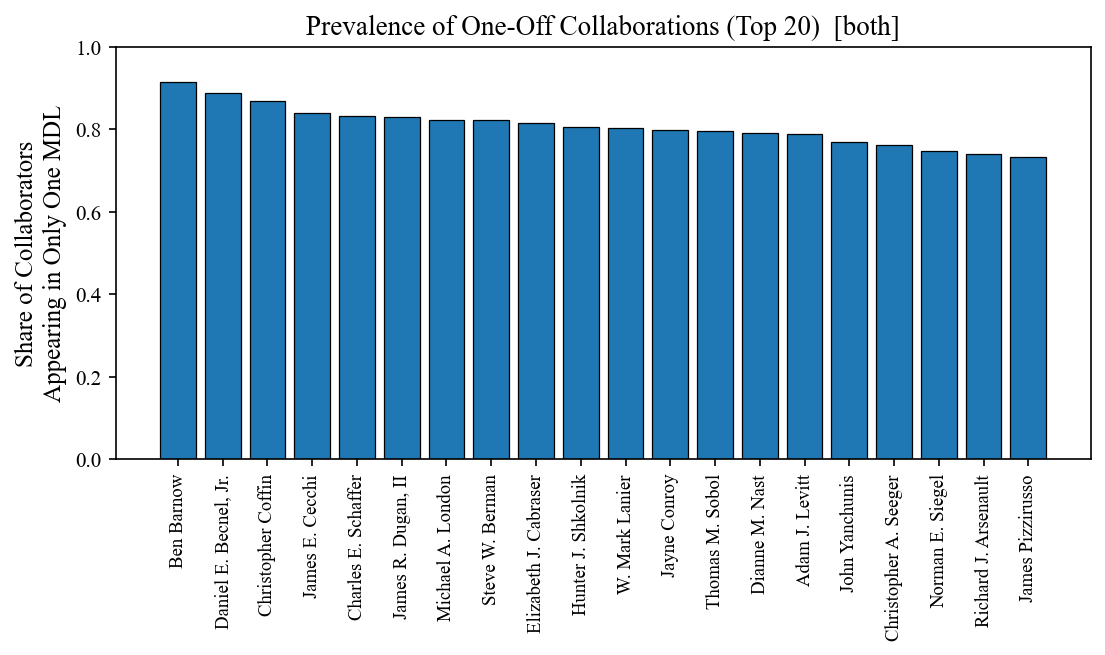

In [5]:
df = attorney_x_mdl.copy()
top20 = df.groupby("attorney_id")["mdl_no"].nunique().sort_values(ascending=False).head(20).index
id_name = df.drop_duplicates("attorney_id").set_index("attorney_id")["canonical_name"]
mdl_slates = df.groupby("mdl_no")["attorney_id"].apply(set)
rows = []
for focal in top20:
    cc = Counter()
    for s in mdl_slates:
        if focal in s:
            for o in s:
                if o != focal: cc[o] += 1
    if cc:
        rows.append({"attorney": id_name.get(focal, focal),
                     "share_once": sum(1 for v in cc.values() if v == 1)/len(cc)})
summ = pd.DataFrame(rows).sort_values("share_once", ascending=False)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(summ["attorney"], summ["share_once"], edgecolor="black", linewidth=0.6)
ax.set_ylim(0, 1.0); ax.set_ylabel("Share of Collaborators\nAppearing in Only One MDL")
ax.set_title(f"Prevalence of One-Off Collaborations (Top 20)  [{SCOPE}]")
ax.set_xticklabels(summ["attorney"], rotation=90)
for sp in ax.spines.values(): sp.set_visible(True); sp.set_linewidth(0.8)
plt.tight_layout(); savefig("fig08_oneoff"); plt.show()


### Figure 9 — Distribution of repeated co-appointment across MDLs (firms)

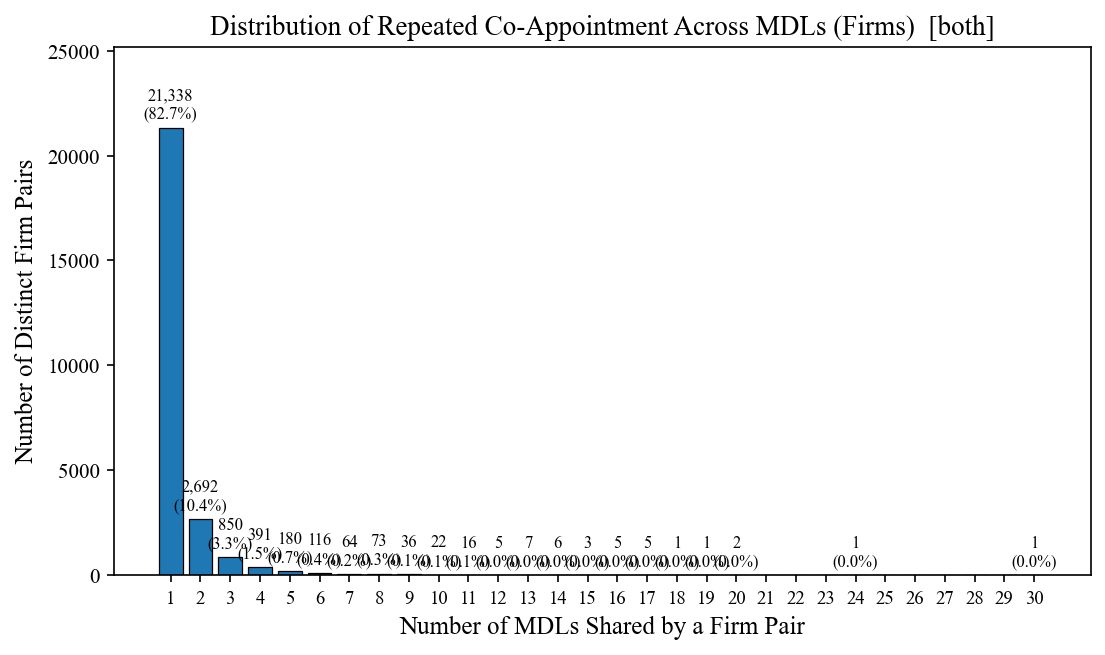

In [6]:
df = firm_x_mdl.copy()
mdl_slates = df.groupby("mdl_no")["firm_id"].apply(set)
firms = sorted(df["firm_id"].unique())
pc = Counter()
for s in mdl_slates:
    for pair in combinations(sorted(s), 2): pc[pair] += 1
shared = pd.Series(list(pc.values()))
dist = shared[shared > 0].value_counts().sort_index()
if len(dist):
    dist = dist.reindex(range(1, dist.index.max() + 1), fill_value=0)
n_nonzero = int(dist.sum())
fig, ax = plt.subplots(figsize=(7.5, 4.5))
bars = ax.bar(dist.index, dist.values, width=0.8, edgecolor="black", linewidth=0.6)
ymax = max(1, dist.values.max()) * 1.18; ax.set_ylim(0, ymax)
ax.set_title(f"Distribution of Repeated Co-Appointment Across MDLs (Firms)  [{SCOPE}]")
ax.set_xlabel("Number of MDLs Shared by a Firm Pair"); ax.set_ylabel("Number of Distinct Firm Pairs")
ax.set_xticks(dist.index)
for sp in ax.spines.values(): sp.set_visible(True); sp.set_linewidth(0.8)
for bar in bars:
    c = int(bar.get_height())
    if c > 0:
        ax.text(bar.get_x()+bar.get_width()/2, c + 0.01*ymax, f"{c:,}\n({c/n_nonzero*100:.1f}%)",
                ha="center", va="bottom", fontsize=8)
plt.tight_layout(); savefig("fig09_firm_coappt_dist"); plt.show()


### Figure 10 — Co-appointment heatmap, top-20 firm pairs

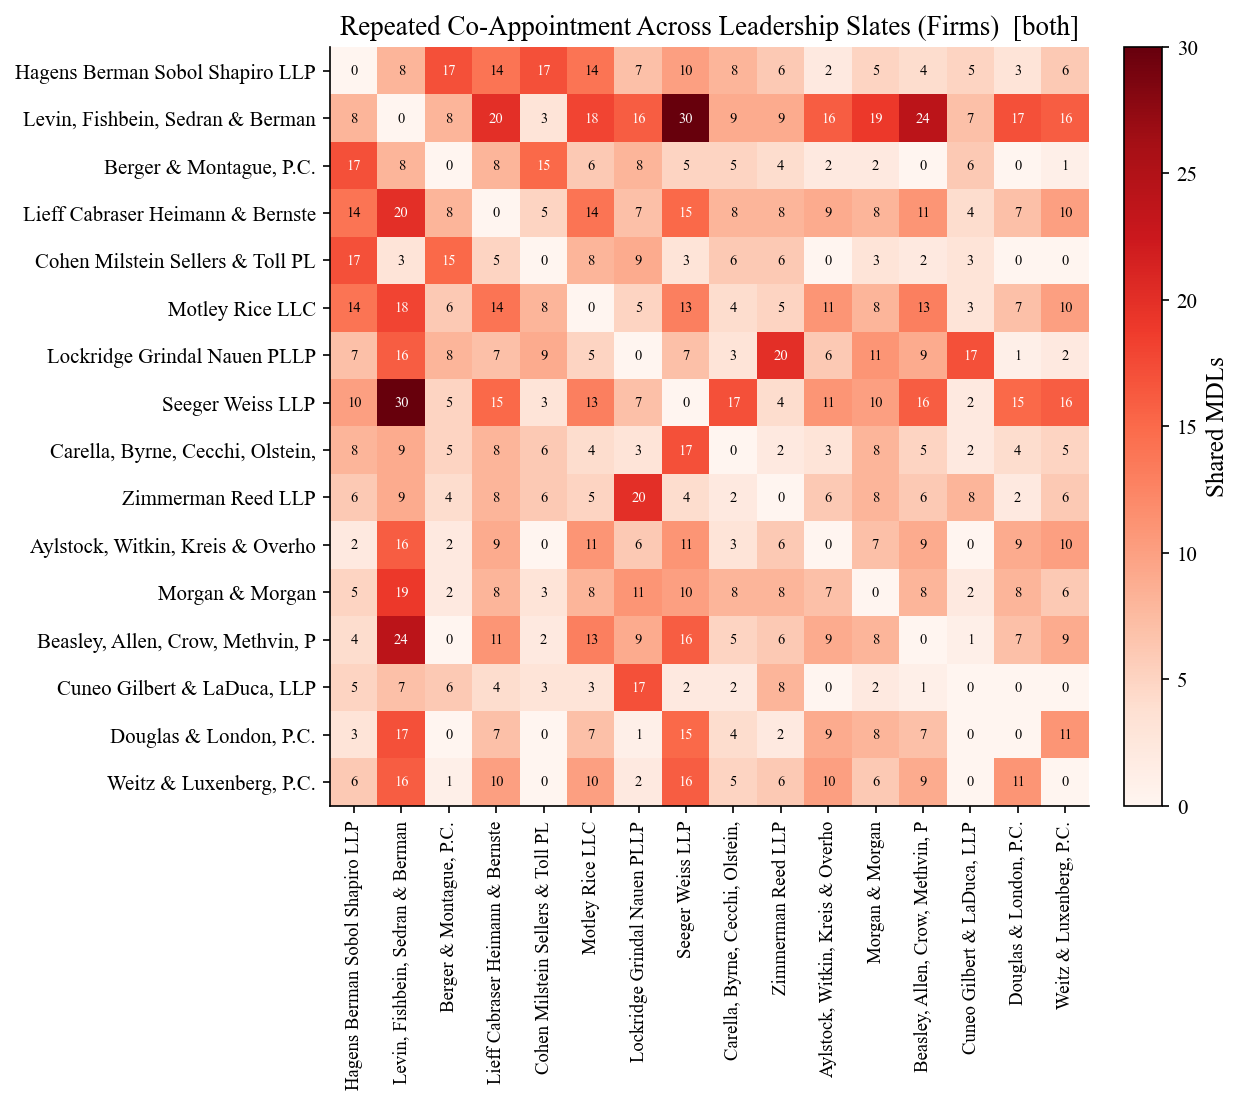

In [7]:
df = firm_x_mdl.copy()
mdl_slates = df.groupby("mdl_no")["firm_id"].apply(lambda x: sorted(set(x)))
pc = Counter()
for s in mdl_slates:
    for a, b in combinations(s, 2): pc[(a, b)] += 1
pair_df = pd.DataFrame([(a, b, c) for (a, b), c in pc.items()], columns=["i", "j", "n"])
top20 = pair_df.sort_values("n", ascending=False).head(20)
top = sorted(set(top20["i"]) | set(top20["j"]))
id_name = df.drop_duplicates("firm_id").set_index("firm_id")["firm"]
if top:
    m = (pair_df[pair_df["i"].isin(top) & pair_df["j"].isin(top)]
         .pivot(index="i", columns="j", values="n").fillna(0))
    m = m.add(m.T, fill_value=0).reindex(index=top, columns=top, fill_value=0).fillna(0).astype(int)
    lab = lambda x: str(id_name.get(x, x))[:32]
    m.index = [lab(i) for i in m.index]; m.columns = [lab(c) for c in m.columns]
    fig, ax = plt.subplots(figsize=(8.5, 7.5))
    im = ax.imshow(m.values, cmap="Reds", vmin=0); ax.set_aspect("equal")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label("Shared MDLs")
    ax.set_xticks(range(len(m.columns))); ax.set_yticks(range(len(m.index)))
    ax.set_xticklabels(m.columns, rotation=90); ax.set_yticklabels(m.index)
    ax.set_title(f"Repeated Co-Appointment Across Leadership Slates (Firms)  [{SCOPE}]")
    mx = m.values.max()
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = int(m.values[i, j])
            ax.text(j, i, v, ha="center", va="center", fontsize=7,
                    color="white" if v >= mx*0.5 and v > 0 else "black")
    plt.tight_layout(); savefig("fig10_firm_heatmap"); plt.show()
else:
    print("no co-appointing firm pairs in scope")


### Figure 11 — Observed vs. capacity-constrained-random co-appointments (Monte Carlo)

[both] observed additional co-appointments: 4,100 | null mean: 1408 | p = 0.0000


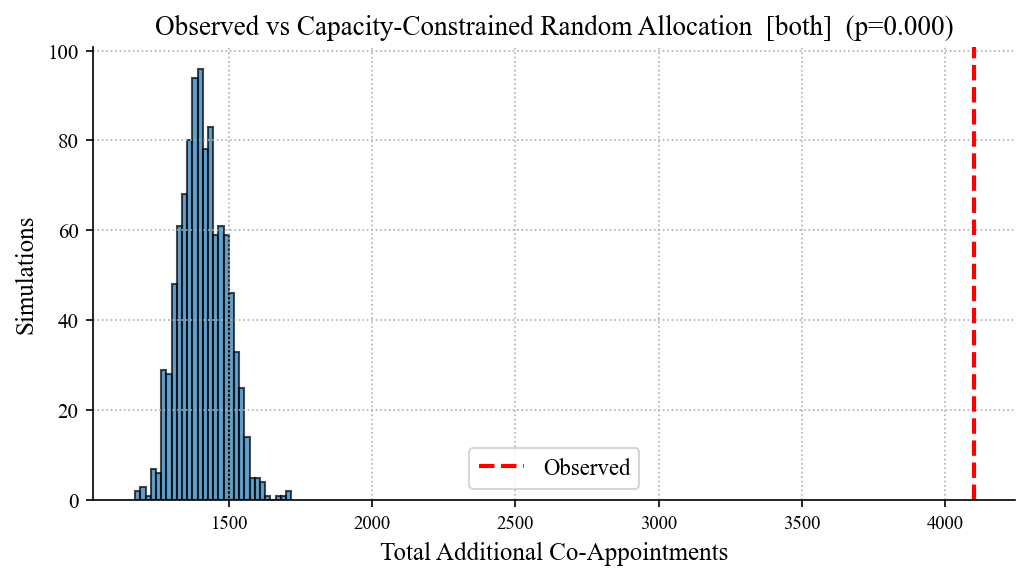

In [8]:
df = attorney_x_mdl.copy()
edges = df[["attorney_id", "mdl_no"]].drop_duplicates()
def additional_coappt(mdl_to_att):
    pc = Counter()
    for atts in mdl_to_att:
        for a, b in combinations(sorted(set(atts)), 2): pc[(a, b)] += 1
    return sum(max(c - 1, 0) for c in pc.values())
observed = additional_coappt(edges.groupby("mdl_no")["attorney_id"].apply(list).values)
cap = edges.groupby("attorney_id")["mdl_no"].nunique().to_dict()
sizes = edges.groupby("mdl_no")["attorney_id"].nunique().to_dict()
mdls_list = list(sizes.keys())
def rand_alloc(seed):
    rng = np.random.default_rng(seed); stubs = []
    for a, c in cap.items(): stubs.extend([a]*c)
    rng.shuffle(stubs); out = []; idx = 0
    for m in mdls_list:
        out.append(stubs[idx:idx+sizes[m]]); idx += sizes[m]
    return out
null = np.array([additional_coappt(rand_alloc(s)) for s in range(1000)])
p = float((null >= observed).mean())
print(f"[{SCOPE}] observed additional co-appointments: {observed:,} | null mean: {null.mean():.0f} | p = {p:.4f}")
plt.figure(figsize=(7, 4))
plt.hist(null, bins=30, edgecolor="black", alpha=0.7)
plt.axvline(observed, color="red", linestyle="--", linewidth=2, label="Observed")
plt.xlabel("Total Additional Co-Appointments"); plt.ylabel("Simulations")
plt.title(f"Observed vs Capacity-Constrained Random Allocation  [{SCOPE}]  (p={p:.3f})")
plt.legend(); plt.grid(True, linestyle=":"); plt.tight_layout(); savefig("fig11_montecarlo"); plt.show()


### Figure 12 — New MDL entrants over time (naïve + rolling 3-year)

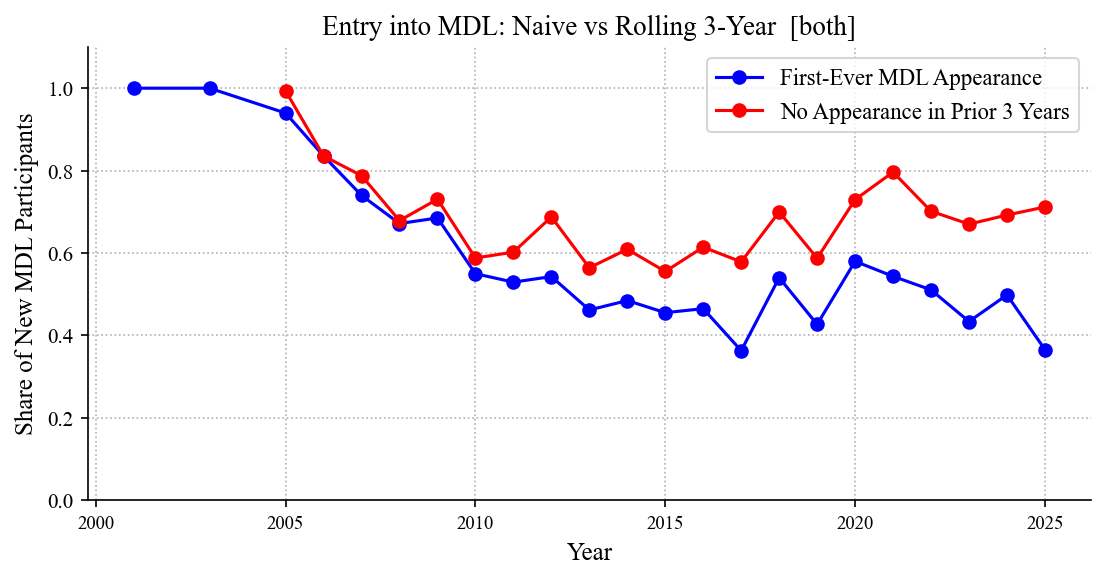

In [9]:
m = mdls.copy()
m["mdl_no"] = pd.to_numeric(m["MDL_NO"], errors="coerce").astype("Int64")
m["date_transferred"] = pd.to_datetime(m["DATE_TRANSFERRED"], errors="coerce", format="mixed")
m["date_filed"] = pd.to_datetime(m["DATE_FILED"], errors="coerce", format="mixed")
m["mdl_date"] = m["date_transferred"].fillna(m["date_filed"])
df = attorney_x_mdl.merge(m[["mdl_no", "mdl_date"]], on="mdl_no", how="left").dropna(subset=["mdl_date"])
df["year"] = df["mdl_date"].dt.year.astype("Int64")
df = df.dropna(subset=["year"])
if len(df):
    fy = df.groupby("attorney_id")["year"].min().rename("first_year").reset_index()
    dn = df.merge(fy, on="attorney_id"); dn["ft"] = (dn["year"] == dn["first_year"]).astype(int)
    yr_all = dn.groupby("year")["attorney_id"].nunique()
    yr_ft = dn[dn["ft"] == 1].groupby("year")["attorney_id"].nunique()
    naive = pd.concat([yr_all, yr_ft], axis=1).fillna(0); naive.columns = ["n", "nft"]
    naive["share"] = naive["nft"] / naive["n"]
    dr = df[["attorney_id", "year"]].drop_duplicates(); rec = []
    y0 = int(dr["year"].min()) + 3   # earliest year with a full 3-year lookback
    for y in sorted(dr["year"].unique()):
        if y < y0: continue
        now = set(dr[dr["year"] == y]["attorney_id"])
        past = set(dr[dr["year"].isin([y-1, y-2, y-3])]["attorney_id"])
        if now: rec.append({"year": y, "share": len(now - past)/len(now)})
    rolling = pd.DataFrame(rec).set_index("year")
    plt.figure(figsize=(7.5, 4))
    plt.plot(naive.index, naive["share"], marker="o", color="blue", label="First-Ever MDL Appearance")
    if len(rolling):
        plt.plot(rolling.index, rolling["share"], marker="o", color="red", label="No Appearance in Prior 3 Years")
    plt.xlabel("Year"); plt.ylabel("Share of New MDL Participants")
    plt.title(f"Entry into MDL: Naive vs Rolling 3-Year  [{SCOPE}]")
    plt.ylim(0, 1.1); plt.grid(True, linestyle=":"); plt.legend(frameon=True)
    plt.tight_layout(); savefig("fig12_entrants"); plt.show()
else:
    print("no dated MDLs in scope")


### Figure 13 — Variation in judges' appointments of first-time leaders

[both] all judges: 343 | median MDLs/judge: 1 | judges with 1 MDL: 239
[both] qualifying judges (>=10 appointments): 187 | median appointments: 21 | median MDLs: 1 | with 1 MDL: 96 | shares at 0 or 1: 3


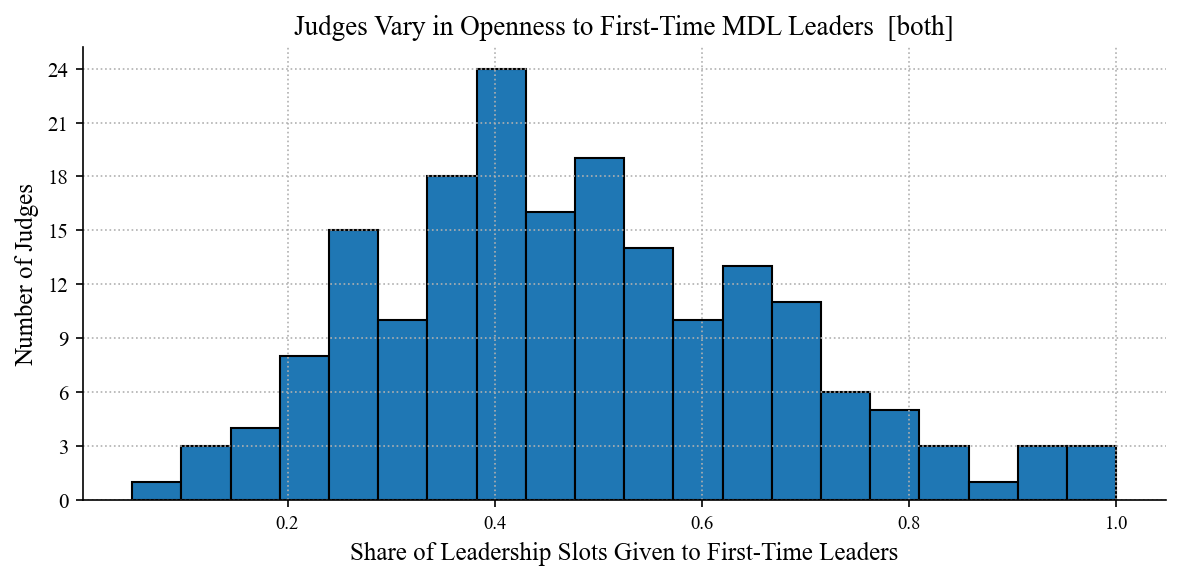

In [10]:
o = orders.copy()
o["mdl_no"] = pd.to_numeric(o["MDL_No"], errors="coerce").astype("Int64")
o = o[["mdl_no", "Judge"]].dropna().rename(columns={"Judge": "judge"})
o["judge"] = o["judge"].astype(str).str.strip()
df = attorney_x_mdl.merge(o.drop_duplicates(), on="mdl_no", how="left").dropna(subset=["judge", "attorney_id", "mdl_no"])
df = df[df["judge"].ne("") & df["judge"].str.lower().ne("nan")]
first = df.groupby("attorney_id")["mdl_no"].min().rename("first_mdl")
df = df.merge(first, on="attorney_id"); df["ft"] = (df["mdl_no"] == df["first_mdl"]).astype(int)
je = df.groupby("judge").agg(total=("attorney_id", "count"), ft=("ft", "sum")).reset_index()
je["share"] = je["ft"] / je["total"]
jm = df.drop_duplicates(["judge", "mdl_no"]).groupby("judge").size().rename("n_mdls")
je = je.merge(jm, on="judge")
print(f"[{SCOPE}] all judges: {len(je)} | median MDLs/judge: {je['n_mdls'].median():.0f} | "
      f"judges with 1 MDL: {(je['n_mdls'] == 1).sum()}")
je = je[je["total"] >= 10]
print(f"[{SCOPE}] qualifying judges (>=10 appointments): {len(je)} | "
      f"median appointments: {je['total'].median():.0f} | median MDLs: {je['n_mdls'].median():.0f} | "
      f"with 1 MDL: {(je['n_mdls'] == 1).sum()} | shares at 0 or 1: {((je['share'] == 0) | (je['share'] == 1)).sum()}")
if len(je):
    from matplotlib.ticker import MaxNLocator
    plt.figure(figsize=(8, 4))
    plt.hist(je["share"], bins=20, edgecolor="black")
    plt.xlabel("Share of Leadership Slots Given to First-Time Leaders"); plt.ylabel("Number of Judges")
    plt.title(f"Judges Vary in Openness to First-Time MDL Leaders  [{SCOPE}]")
    plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))
    plt.grid(True, linestyle=":"); plt.tight_layout(); savefig("fig13_judges"); plt.show()


## 3 — Appendix figures (geography, gender, age)

### Appendix Fig 1 & 3 — Appointments by bar state (choropleth): all + LeadCounsel

In [11]:
import plotly.express as px, plotly.graph_objects as go
STATE_C = pd.DataFrame({
 "state":["AL","AK","AZ","AR","CA","CO","CT","DE","FL","GA","HI","ID","IL","IN","IA","KS","KY","LA","ME","MD","MA","MI","MN","MS","MO","MT","NE","NV","NH","NJ","NM","NY","NC","ND","OH","OK","OR","PA","RI","SC","SD","TN","TX","UT","VT","VA","WA","WV","WI","WY"],
 "lat":[32.8,61.3,34.2,35.2,36.8,39.6,41.6,39.0,27.8,32.7,20.8,44.1,40.0,40.3,42.0,38.5,37.5,31.2,45.3,39.0,42.3,43.3,46.7,32.6,38.5,46.9,41.5,39.5,43.2,40.1,34.8,43.0,35.8,47.5,40.4,35.6,44.0,41.2,41.7,33.8,44.4,35.7,31.0,39.3,44.3,37.7,47.3,38.6,44.5,43.1],
 "lon":[-86.8,-149.5,-111.9,-92.3,-119.4,-105.3,-72.7,-75.5,-81.7,-83.1,-157.5,-114.7,-89.0,-86.1,-93.5,-98.0,-85.0,-91.9,-69.0,-76.8,-71.8,-84.7,-94.5,-89.7,-92.4,-110.4,-99.7,-116.6,-71.6,-74.7,-105.0,-75.5,-78.7,-100.5,-82.8,-97.5,-120.6,-77.8,-71.6,-80.9,-100.3,-86.4,-100.0,-78.5,-72.7,-79.0,-120.5,-80.5,-89.6,-107.3]})

def bar_state_counts(df):
    t = df[["Bar_States"]].dropna().copy()
    t["Bar_States"] = t["Bar_States"].astype(str)
    t["lst"] = t["Bar_States"].str.split(r"[;,]")
    t = t.explode("lst"); t["lst"] = t["lst"].str.strip()
    t["state"] = t["lst"].str[:2].str.upper()
    t = t[t["state"].str.match(r"^[A-Z]{2}$").fillna(False)]
    return t["state"].value_counts().rename_axis("state").reset_index(name="count")

def choropleth(df, title, scale):
    sc = bar_state_counts(df).merge(STATE_C, on="state", how="left")
    fig = px.choropleth(sc, locations="state", locationmode="USA-states", color="count",
                        color_continuous_scale=scale, scope="usa", title=f"{title}  [{SCOPE}]")
    fig.add_trace(go.Scattergeo(locationmode="USA-states", lon=sc["lon"], lat=sc["lat"],
                  text=sc["state"], mode="text", textfont=dict(size=9, color="black"), showlegend=False))
    fig.update_layout(geo=dict(bgcolor="rgba(0,0,0,0)"))
    return fig

lead = appointments_attorneys[appointments_attorneys["Appointment Types"].fillna("").str.contains("LeadCounsel", case=False)]
choropleth(appointments_attorneys, "Appointments by Bar State", "YlOrBr").show()
choropleth(lead, "LeadCounsel Appointments by Bar State", "Reds").show()


### Appendix Fig 2 & 4 — Appointments per bar state (bar chart): all + LeadCounsel

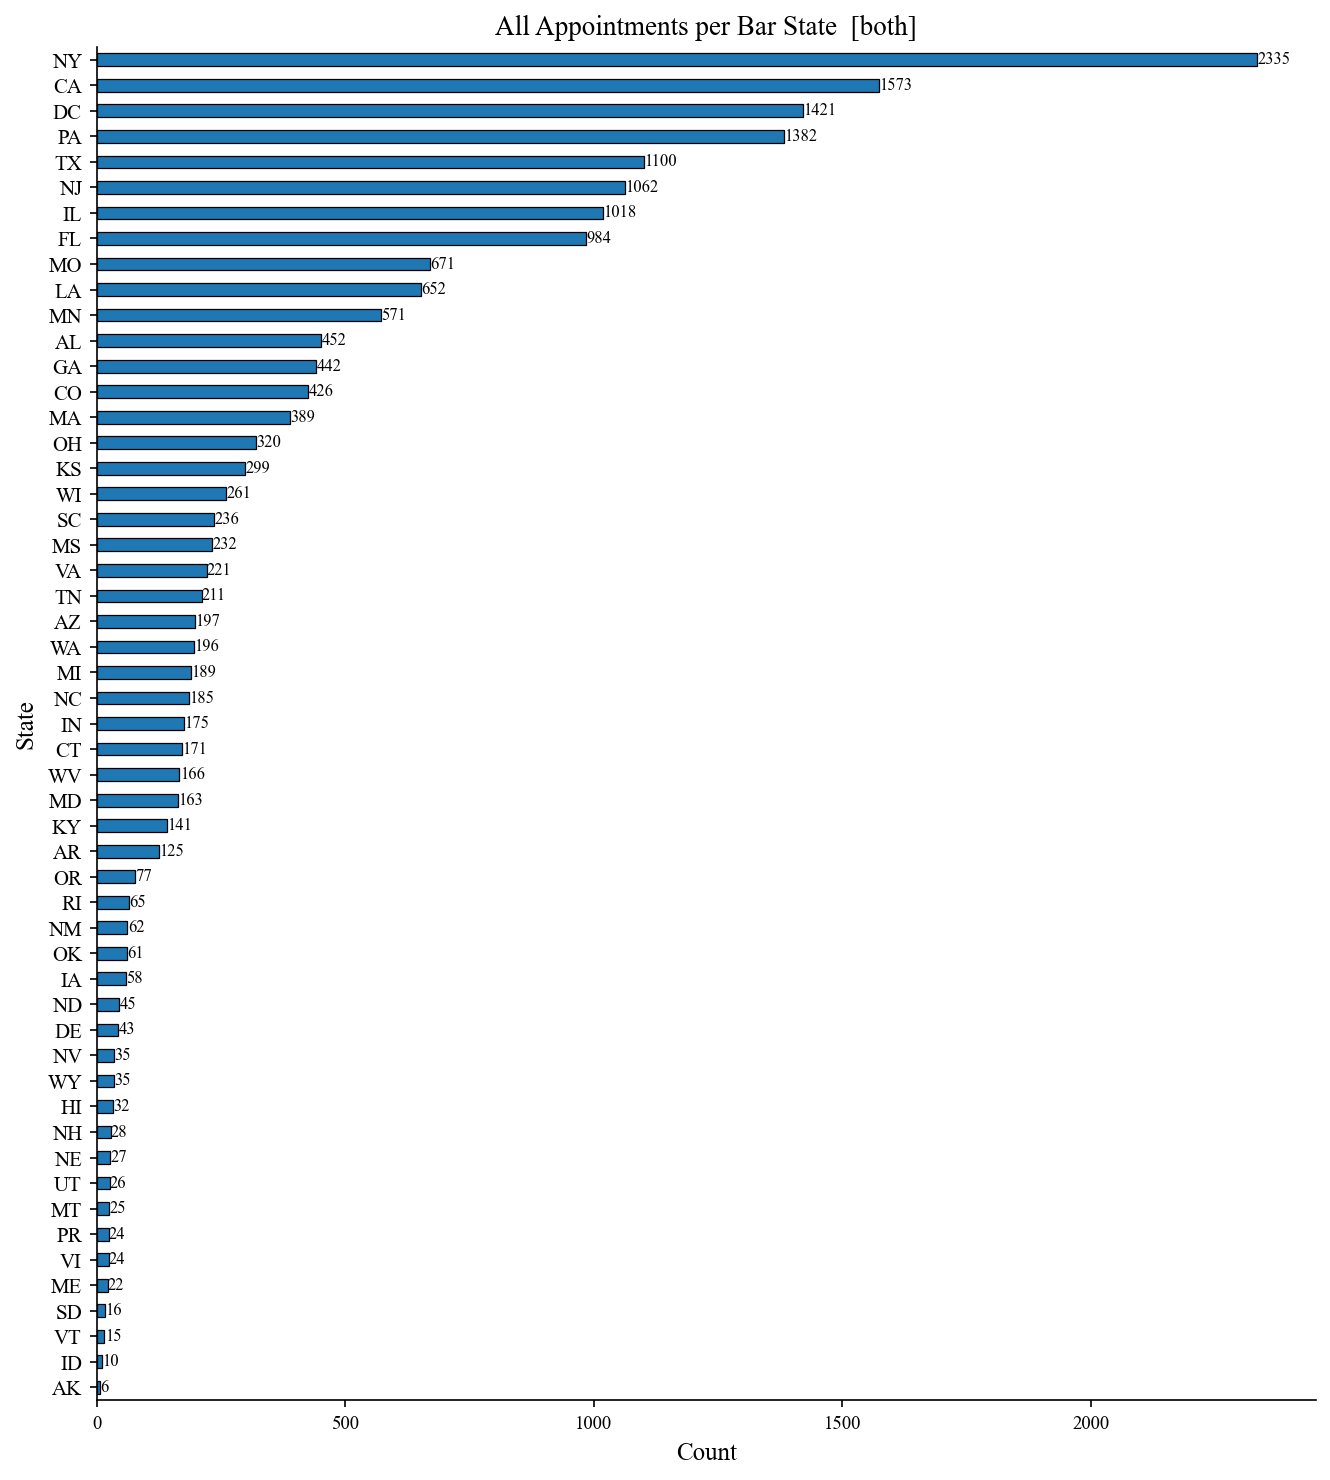

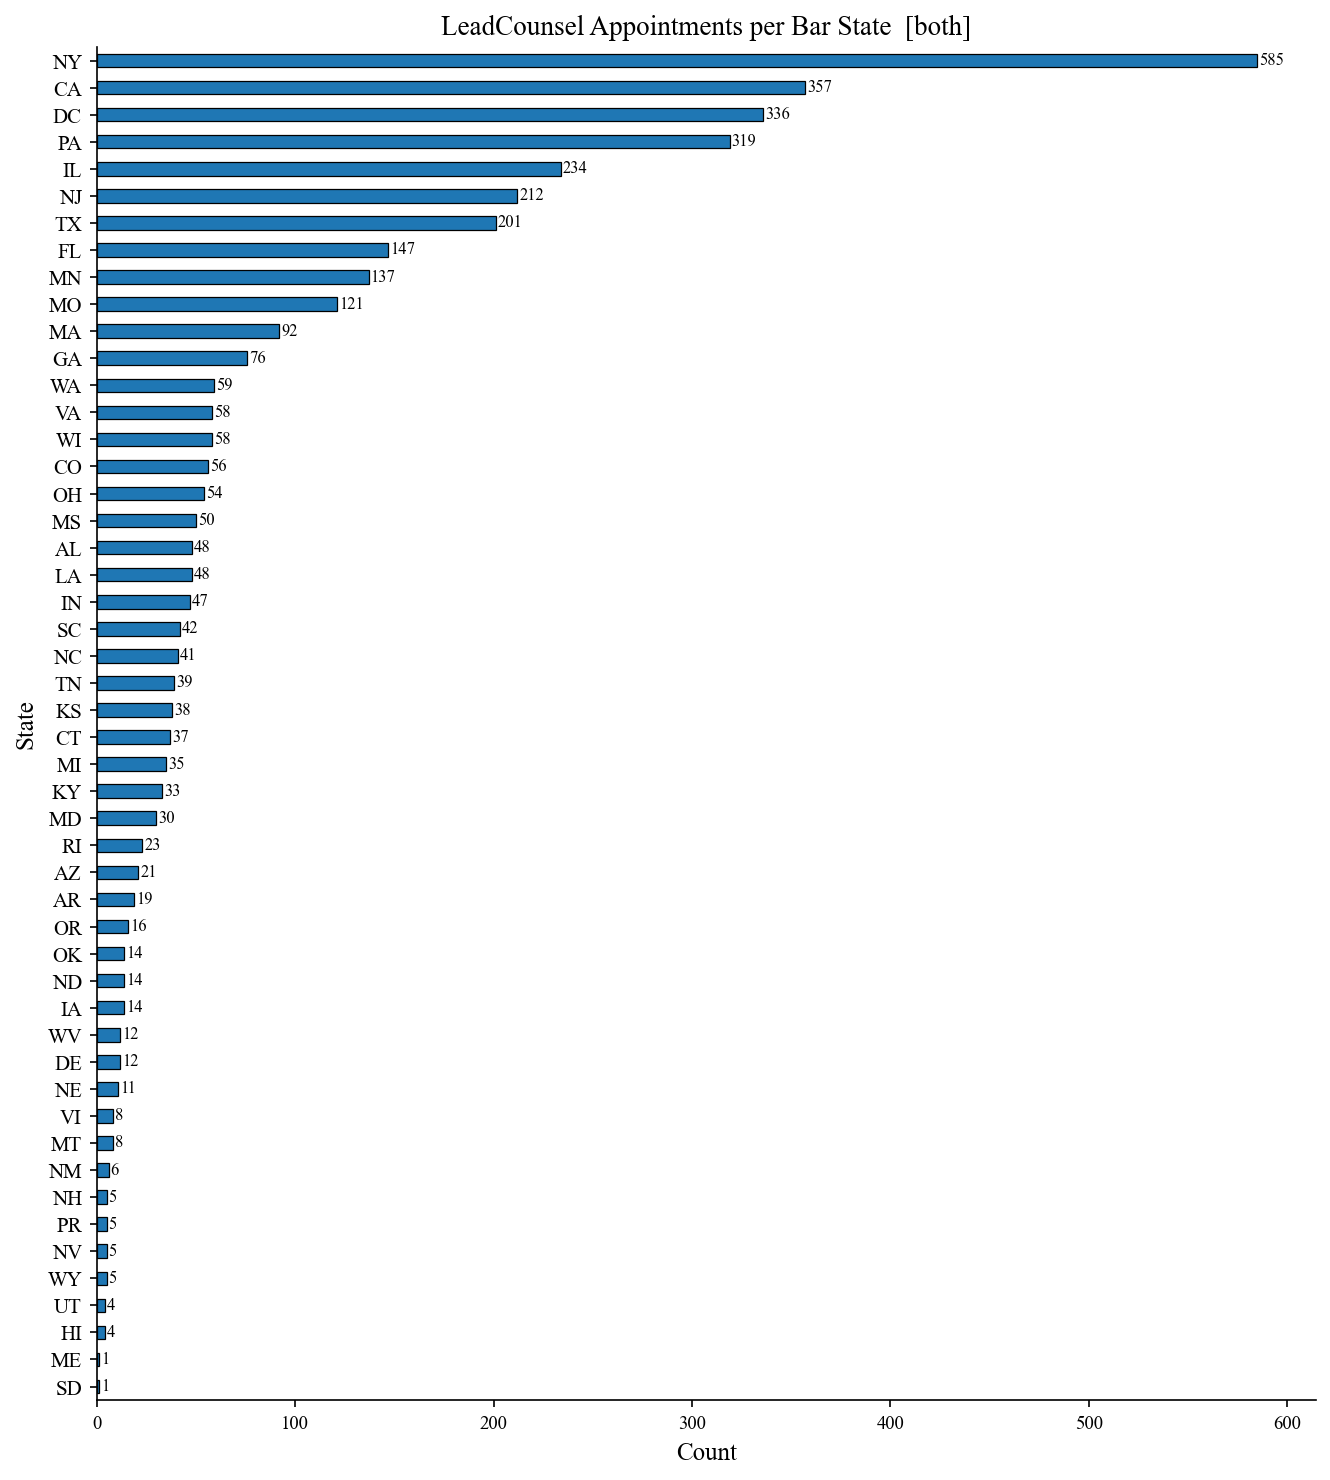

In [12]:
def barstate_plot(df, title):
    sc = bar_state_counts(df).set_index("state")["count"].sort_values()
    plt.figure(figsize=(9, 10)); sc.plot(kind="barh", edgecolor="black", linewidth=0.6)
    plt.title(f"{title}  [{SCOPE}]"); plt.xlabel("Count"); plt.ylabel("State")
    for i, v in enumerate(sc): plt.text(v + 1, i, str(int(v)), va="center", fontsize=8)
    plt.tight_layout()
barstate_plot(appointments_attorneys, "All Appointments per Bar State"); savefig("figA2_barstate_all"); plt.show()
barstate_plot(lead, "LeadCounsel Appointments per Bar State"); savefig("figA4_barstate_lead"); plt.show()


### Appendix Fig 5 & 6 — Gender distribution: all + LeadCounsel

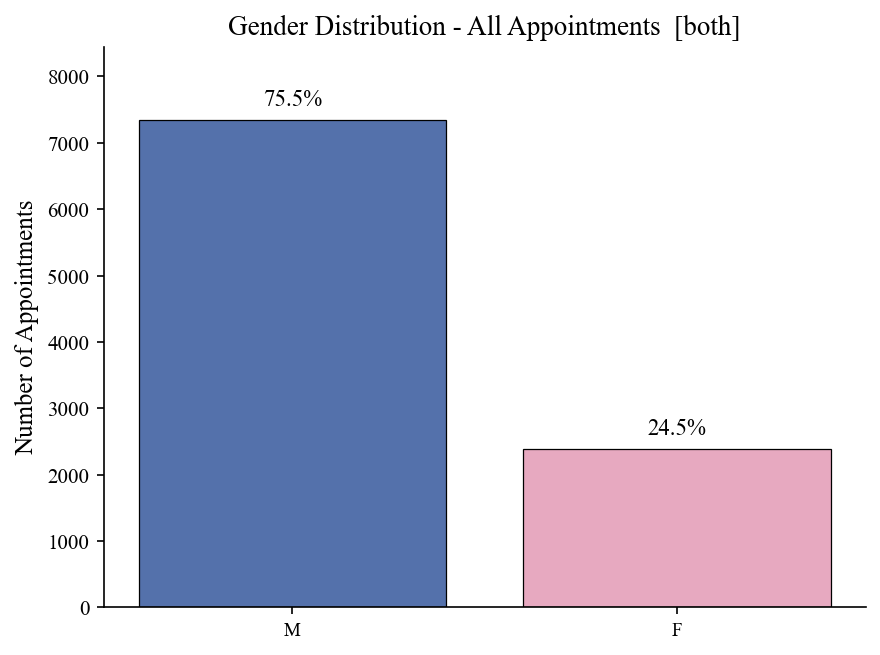

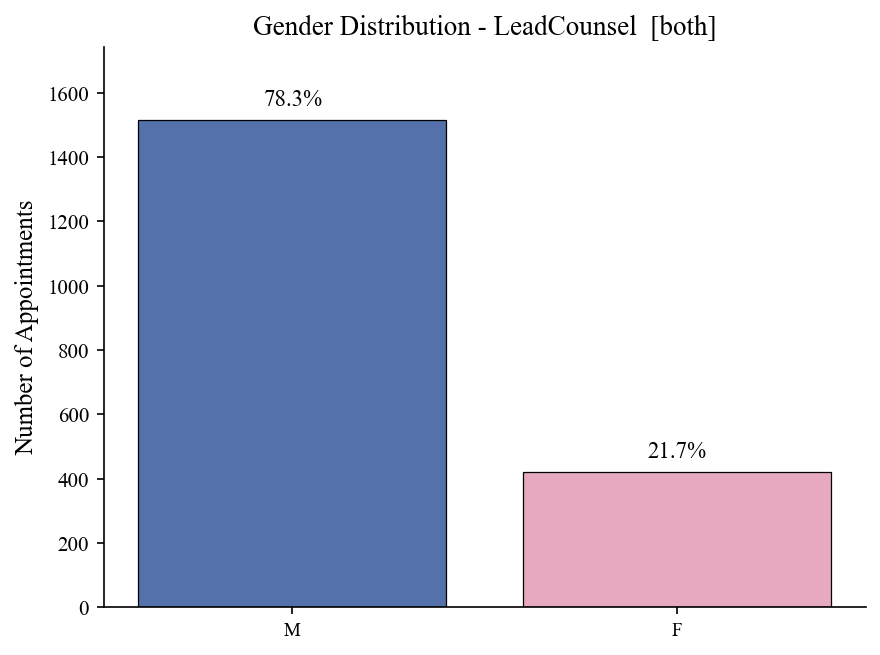

In [13]:
def gender_norm(df):
    df = df.copy(); df["g"] = df["Gender"].astype(str).str.strip().str.upper().str[0]
    return df[df["g"].isin(["M", "F"])]
def gender_plot(df, title):
    g = gender_norm(df); vc = g["g"].value_counts(); pct = (vc/vc.sum()*100).round(1)
    vc = vc.sort_values(ascending=False); pct = pct[vc.index]
    colors = ["#5471AB" if k == "M" else "#E7A9C0" for k in vc.index]
    plt.figure(figsize=(6, 4.5)); bars = plt.bar(vc.index, vc.values, color=colors, edgecolor="black", linewidth=0.6)
    plt.title(f"{title}  [{SCOPE}]"); plt.ylabel("Number of Appointments"); plt.ylim(0, vc.max()*1.15)
    for b, p in zip(bars, pct):
        plt.text(b.get_x()+b.get_width()/2, b.get_height()+vc.max()*0.02, f"{p}%", ha="center", va="bottom")
    plt.tight_layout()
gender_plot(appointments_attorneys, "Gender Distribution - All Appointments"); savefig("figA5_gender_all"); plt.show()
if len(gender_norm(lead)): gender_plot(lead, "Gender Distribution - LeadCounsel"); savefig("figA6_gender_lead"); plt.show()


### Appendix Fig 7 & 8 — Age at MDL transfer: all + LeadCounsel

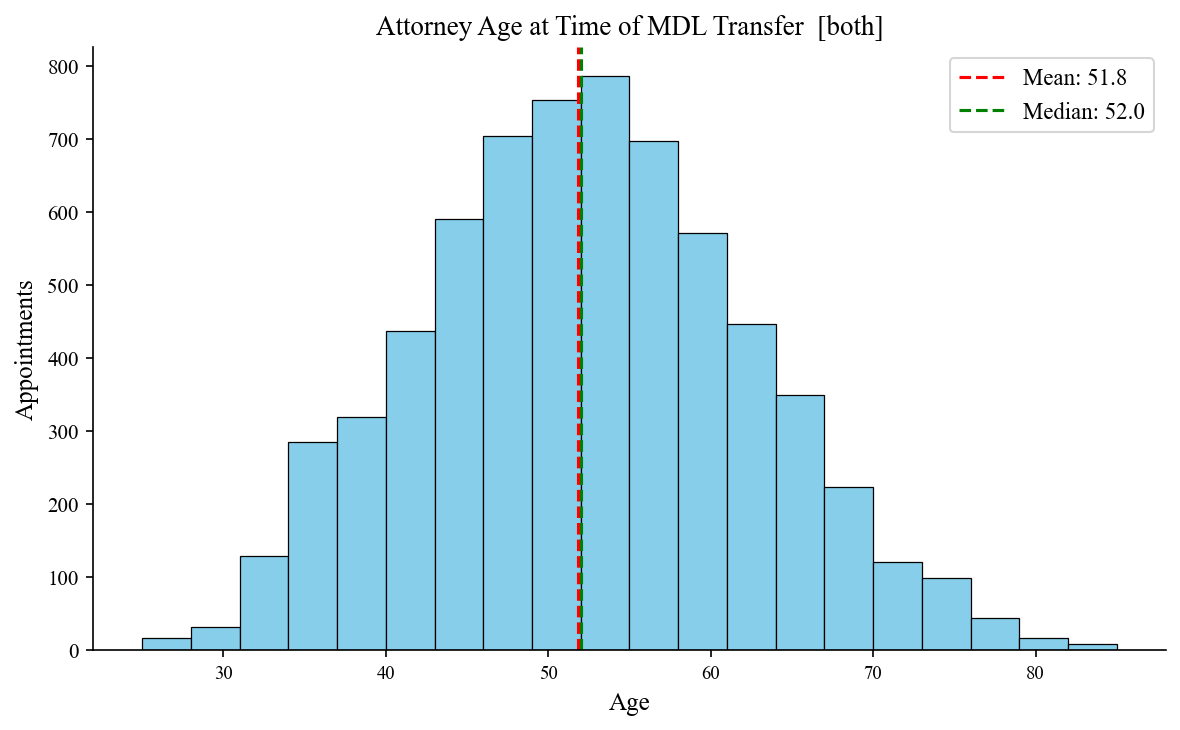

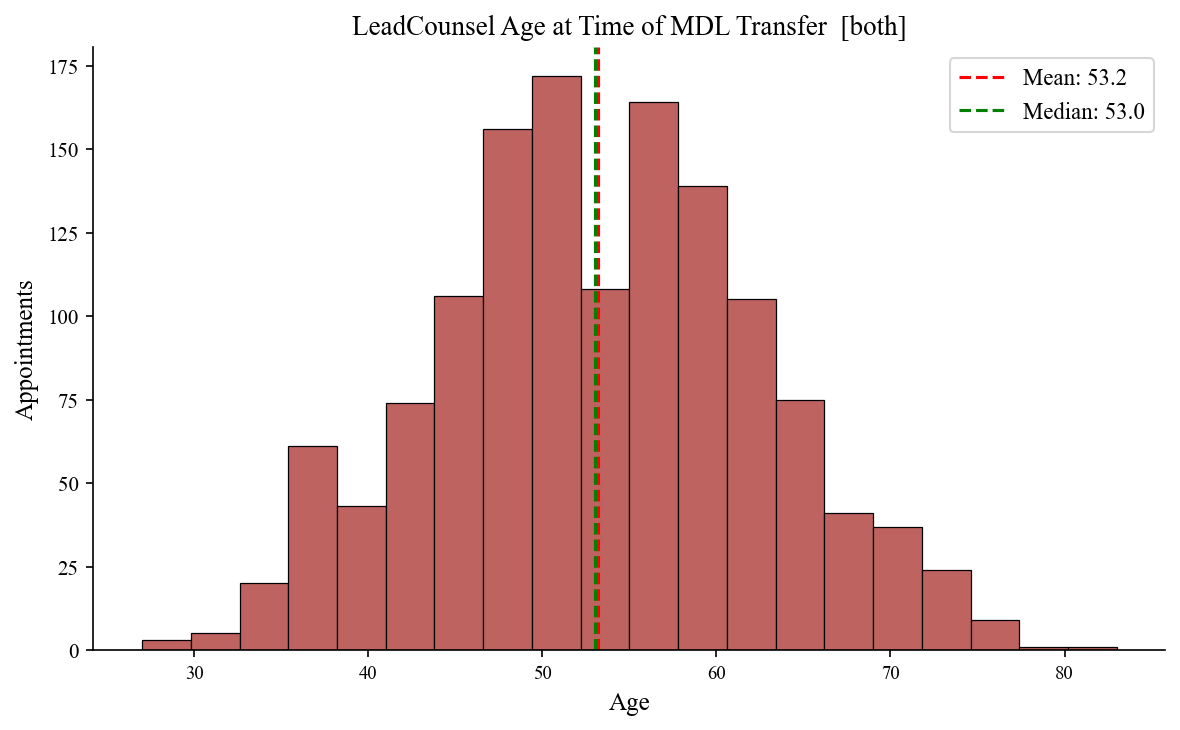

In [14]:
m = mdls.copy()
m["mdl_no"] = pd.to_numeric(m["MDL_NO"], errors="coerce").astype("Int64")
m["date_transferred"] = pd.to_datetime(m["DATE_TRANSFERRED"], errors="coerce", format="mixed")
def age_plot(df, title, color):
    d = df.merge(m[["mdl_no", "date_transferred"]], left_on="mdl_no", right_on="mdl_no", how="left")
    d = d.dropna(subset=["Birth_Year", "date_transferred"]).copy()
    d["Birth_Year"] = pd.to_numeric(d["Birth_Year"], errors="coerce")
    d = d.dropna(subset=["Birth_Year"])
    d["age"] = d["date_transferred"].dt.year - d["Birth_Year"].astype(int)
    d = d[(d["age"] > 20) & (d["age"] < 95)]
    if not len(d): print(f"no age data [{title}]"); return
    plt.figure(figsize=(8, 5)); plt.hist(d["age"], bins=20, color=color, edgecolor="black", linewidth=0.6)
    plt.axvline(d["age"].mean(), color="red", linestyle="--", label=f"Mean: {d['age'].mean():.1f}")
    plt.axvline(d["age"].median(), color="green", linestyle="--", label=f"Median: {d['age'].median():.1f}")
    plt.title(f"{title}  [{SCOPE}]"); plt.xlabel("Age"); plt.ylabel("Appointments"); plt.legend(); plt.tight_layout()
# needs mdl_no on appointments_attorneys
aa = appointments_attorneys.copy()
aa["mdl_no"] = pd.to_numeric(aa["MDL_No"], errors="coerce").astype("Int64").replace(PELVIC, 9999)
aa_lead = aa[aa["Appointment Types"].fillna("").str.contains("LeadCounsel", case=False)]
age_plot(aa, "Attorney Age at Time of MDL Transfer", "skyblue"); savefig("figA7_age_all"); plt.show()
age_plot(aa_lead, "LeadCounsel Age at Time of MDL Transfer", "#BF6360"); savefig("figA8_age_lead"); plt.show()


## 4 — Part III.2: Cycling in attorney leadership roles

In [15]:
df = attorney_x_mdl[["mdl_no", "attorney_id", "is_lead"]].copy()
rows = []
for mdl, g in df.groupby("mdl_no"):
    roles = dict(zip(g["attorney_id"], g["is_lead"]))
    for a, b in combinations(sorted(roles), 2):
        if roles[a] and not roles[b]: rows.append((a, b, "A>B"))
        elif roles[b] and not roles[a]: rows.append((a, b, "B>A"))
pairs = pd.DataFrame(rows, columns=["a", "b", "cat"])
if len(pairs):
    summ = pairs.groupby(["a", "b"])["cat"].apply(set).reset_index()
    summ["cycling"] = summ["cat"].apply(lambda s: "A>B" in s and "B>A" in s)
    rate = summ["cycling"].mean() * 100
    print(f"[{SCOPE}] hierarchical (lead/non-lead) pairs: {len(summ):,} | cycling rate: {rate:.2f}%")
else:
    print(f"[{SCOPE}] no hierarchical pairs")


[both] hierarchical (lead/non-lead) pairs: 12,243 | cycling rate: 1.36%
